In [11]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import PercentFormatter

DEM, REP, GRAY = "#2a78d6", "#e34948", "#8a8984"  # цвета партий
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
})

In [12]:
RAW = Path("../data/raw/1976-2024-president.csv")
URL = "https://dataverse.harvard.edu/api/access/datafile/13887042"

if not RAW.exists():
    RAW.parent.mkdir(parents=True, exist_ok=True)
    request = urllib.request.Request(URL, headers={"User-Agent": "election-ml-project"})
    RAW.write_bytes(urllib.request.urlopen(request).read())

raw = pd.read_csv(RAW)
print(raw.shape)
raw.head()

(4822, 15)


,year,state,state_po,state_fips,state_cen,state_ic,office,candidate,party_detailed,writein,candidatevotes,totalvotes,version,notes,party_simplified
0,1976,ALABAMA,AL,1,63,41.0,US PRESIDENT,"BUBAR, BENJAMIN """"BEN""""",PROHIBITION,False,6669,1182850,20210113,NaN,OTHER
1,1976,ALABAMA,AL,1,63,41.0,US PRESIDENT,"CARTER, JIMMY",DEMOCRAT,False,659170,1182850,20210113,NaN,DEMOCRAT
2,1976,ALABAMA,AL,1,63,41.0,US PRESIDENT,"FORD, GERALD",REPUBLICAN,False,504070,1182850,20210113,NaN,REPUBLICAN
3,1976,ALABAMA,AL,1,63,41.0,US PRESIDENT,"HALL, GUS",COMMUNIST PARTY USE,False,1954,1182850,20210113,NaN,OTHER
4,1976,ALABAMA,AL,1,63,41.0,US PRESIDENT,"MACBRIDE, ROGER",LIBERTARIAN,False,1481,1182850,20210113,NaN,LIBERTARIAN



| колонка | это |
|---|---|
| `year`, `state_po` | год и код штата (`CA`, `TX`, …; `DC` — округ Колумбия) |
| `candidate` | кандидат |
| `party_simplified` | партия: DEMOCRAT, REPUBLICAN, LIBERTARIAN, OTHER |
| `candidatevotes` | сколько голосов получил кандидат в штате |

13 выборов × 51 штат 

In [13]:
print("годы:", sorted(raw.year.unique().tolist()))
print("штатов в каждом году:", raw.groupby("year").state_po.nunique().unique())
raw.party_simplified.value_counts()

годы: [1976, 1980, 1984, 1988, 1992, 1996, 2000, 2004, 2008, 2012, 2016, 2020, 2024]
штатов в каждом году: [51]


party_simplified
OTHER          2909
DEMOCRAT        666
REPUBLICAN      664
LIBERTARIAN     582
Name: count, dtype: int64

In [14]:
raw.query("state_po == 'NY' and year == 2016 and candidatevotes > 100_000")[
    ["candidate", "party_detailed", "party_simplified", "candidatevotes"]
]

,candidate,party_detailed,party_simplified,candidatevotes
3622,"CLINTON, HILLARY",DEMOCRAT,DEMOCRAT,4379789
3623,"CLINTON, HILLARY",WORKING FAMILIES,OTHER,140041
3625,"JOHNSON, GARY",INDEPENDENCE,OTHER,119156
3628,"STEIN, JILL",GREEN,OTHER,107934
3629,"TRUMP, DONALD J.",REPUBLICAN,REPUBLICAN,2527142
3630,"TRUMP, DONALD J.",CONSERVATIVE,OTHER,292392


In [15]:
major = raw[raw.party_simplified.isin(["DEMOCRAT", "REPUBLICAN"])]
nominees = (
    major.groupby(["year", "party_simplified", "candidate"])["candidatevotes"].sum()
    .reset_index()
    .sort_values("candidatevotes")
    .drop_duplicates(["year", "party_simplified"], keep="last")  # оставляем самого популярного
)
nominees.pivot(index="year", columns="party_simplified", values="candidate")

party_simplified,DEMOCRAT,REPUBLICAN
year,,
1976,"CARTER, JIMMY","FORD, GERALD"
1980,"CARTER, JIMMY","REAGAN, RONALD"
1984,"MONDALE, WALTER","REAGAN, RONALD"
1988,"DUKAKIS, MICHAEL","BUSH, GEORGE H.W."
1992,"CLINTON, BILL","BUSH, GEORGE H.W."
1996,"CLINTON, BILL","DOLE, ROBERT"
2000,"GORE, AL","BUSH, GEORGE W."
2004,"KERRY, JOHN","BUSH, GEORGE W."
2008,"OBAMA, BARACK H.","MCCAIN, JOHN"


In [16]:
nominees = nominees.rename(columns={"party_simplified": "party"})[["year", "party", "candidate"]]
votes = raw.merge(nominees, on=["year", "candidate"])  # оставляем только строки номинантов
results = votes.pivot_table(index=["year", "state_po"], columns="party",
                            values="candidatevotes", aggfunc="sum").reset_index()
results.columns = ["year", "state", "dem_votes", "rep_votes"]

results["dem_share"] = results.dem_votes / (results.dem_votes + results.rep_votes)
results["dem_win"] = (results.dem_share > 0.5).astype(int)
results.head()

,year,state,dem_votes,rep_votes,dem_share,dem_win
0,1976,AK,44058,71555,0.381082,0
1,1976,AL,659170,504070,0.566667,1
2,1976,AR,498604,267903,0.650489,1
3,1976,AZ,295602,418642,0.413867,0
4,1976,CA,3742284,3882244,0.490822,0


In [17]:
national = results.groupby("year")[["dem_votes", "rep_votes"]].sum()
national["dem_share"] = national.dem_votes / (national.dem_votes + national.rep_votes)
national["dem_states"] = results.groupby("year").dem_win.sum()
national[["dem_share", "dem_states"]].round(3)

,dem_share,dem_states
year,,
1976,0.511,24
1980,0.447,7
1984,0.408,2
1988,0.461,11
1992,0.535,33
1996,0.547,32
2000,0.503,21
2004,0.488,20
2008,0.537,29


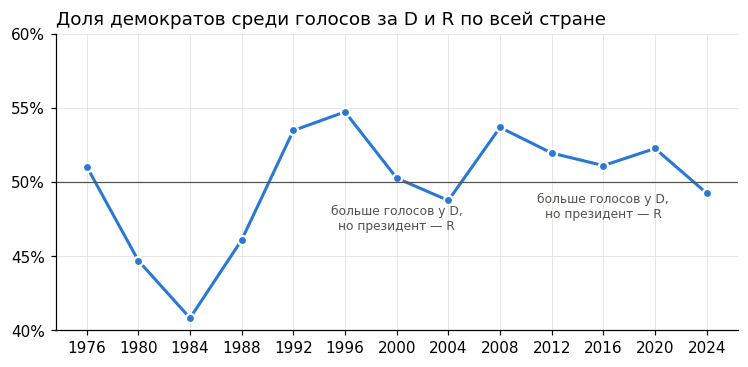

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(national.index, national.dem_share, color=DEM, lw=2, marker="o", ms=6,
        markeredgecolor="white", markeredgewidth=1.5)
ax.axhline(0.5, color="#52514e", lw=0.8)
for year in [2000, 2016]:
    ax.annotate("больше голосов у D,\nно президент — R", (year, national.dem_share[year]),
                xytext=(0, -34), textcoords="offset points", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(national.index)
ax.set_yticks([0.40, 0.45, 0.50, 0.55, 0.60])
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Доля демократов среди голосов за D и R по всей стране", loc="left")
plt.show()

В 2000 и 2016 годах демократы получили больше голосов по стране, но проиграли выборы. 
Президента выбирает коллегия выборщиков: почти во всех штатах победитель штата забирает всех его выборщиков. 


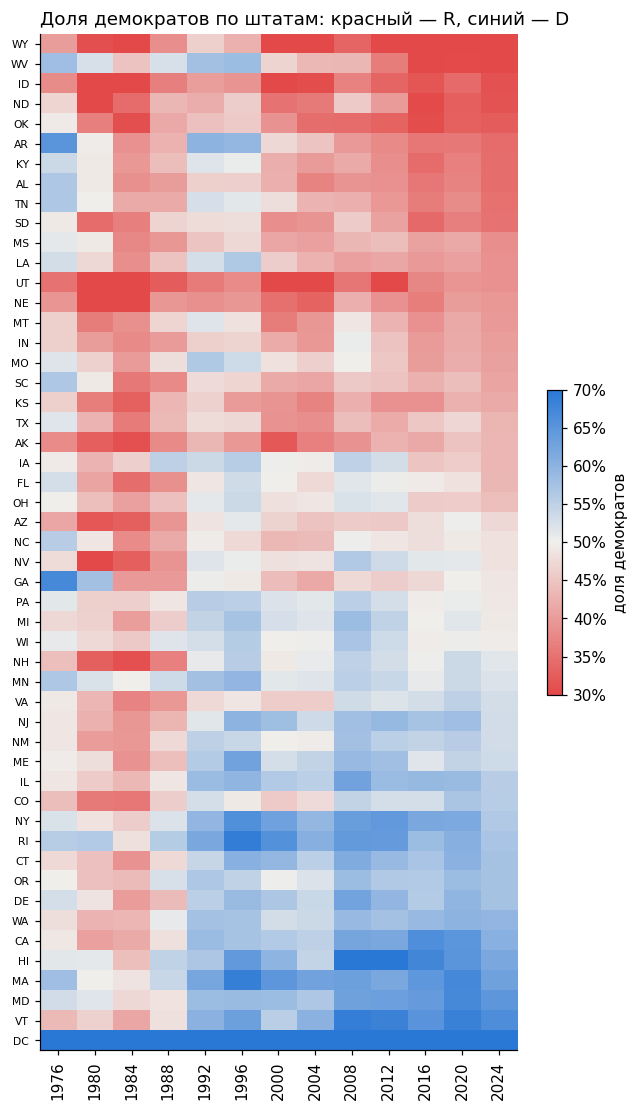

In [19]:
table = results.pivot(index="state", columns="year", values="dem_share")
table = table.loc[table[2024].sort_values().index]

cmap = LinearSegmentedColormap.from_list("party", [REP, "#f0efec", DEM])
fig, ax = plt.subplots(figsize=(7, 12))
image = ax.imshow(table, cmap=cmap, norm=TwoSlopeNorm(vmin=0.3, vcenter=0.5, vmax=0.7), aspect="auto")
ax.set_xticks(range(len(table.columns)), table.columns, rotation=90)
ax.set_yticks(range(len(table)), table.index, fontsize=7)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.3, label="доля демократов", format=PercentFormatter(1, decimals=0))
ax.set_title("Доля демократов по штатам: красный — R, синий — D", loc="left")
plt.show()

1. **Штаты устойчивы.** 
2. **Штаты медленно дрейфуют.**
3. **Бывают общенациональные «волны».** Важно общее настроение страны.



In [20]:
OUT = Path("../data/processed/state_results.csv")
OUT.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(OUT, index=False)
print(f"Сохранено {len(results)} строк в {OUT}")

Сохранено 663 строк в ..\data\processed\state_results.csv
